# Edge basics

In [1]:
# barebones version of edge pipeline 
# works out sobel and canny for every image turns them into simple features
# and prints what the features look like for each class
# no svm yet

# how to run
#   keep this in the edge folder next to the Dataset folder and folds csv
#   python edge_basics.py

# order of the file
#   1 settings
#   2 load data the same way as the setup notebook
#   3 preprocessing
#   4 sobel and canny
#   5 features
#   6 compute features for every image
#   7 print results
#   8 example picture

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

## 1 settings

In [2]:

# 1 settings

# folder with the Dataset folder and folds csv in it
DATA_ROOT = Path.cwd().parent
FOLDS_CSV = DATA_ROOT / "folds.csv"

# class names in id order same as the setup notebook
CLASS_NAMES = ["Crack", "Pothole", "Surface Erosion"]

# original image size and size of image we want to use (256)
IMAGE_SIZE = 640
EDGE_SIZE = 256

# light blur before sobel for noise reduction
BLUR_SIGMA = 1.0

# stretch the brightness of every image before sobel and canny
# turned off in one robustness cell to show what it fixes
NORMALISE = True

# canny thresholds
CANNY_LOW = 50
CANNY_HIGH = 150

# work the canny thresholds out per image from the median brightness instead
# turned on in one robustness cell to compare against the fixed ones
CANNY_AUTO = False

# 9 bins over 0 to 180 degrees so each bin is 20 degrees
N_BINS = 9

# 2 means split the image into 4 boxes
GRID = 2

# set to a number like 20 for a quick run or None for every image
QUICK_TEST_PER_CLASS = None

# where outputs get saved
OUTPUT_DIR = Path.cwd() / "basics_output"

## 2 load data the same way as the setup notebook

In [3]:
# 2 load data the same way as the setup notebook

def load_table():
    # folds csv has columns path class_name class_id fold
    table = pd.read_csv(FOLDS_CSV)
    table["full_path"] = [str(DATA_ROOT / p) for p in table["path"]]

    # optional smaller run
    if QUICK_TEST_PER_CLASS is not None:
        pieces = []
        for class_id in range(len(CLASS_NAMES)):
            rows = table[table["class_id"] == class_id]
            pieces.append(rows.sample(min(len(rows), QUICK_TEST_PER_CLASS), random_state=42))
        table = pd.concat(pieces)

    return table.reset_index(drop=True)


def load_image(path):
    # same as load image in the setup notebook
    # rgb and if not 640 by 640 cut the middle square out then resize
    with Image.open(path) as im:
        img = im.convert("RGB")
    w, h = img.size
    if (w, h) != (IMAGE_SIZE, IMAGE_SIZE):
        side = min(w, h)
        left = (w - side) // 2
        top = (h - side) // 2
        img = img.crop((left, top, left + side, top + side)).resize((IMAGE_SIZE, IMAGE_SIZE))
    return np.array(img)

## 3 preprocessing

In [4]:
# 3 preprocessing

def prepare_image(rgb):
    # gray then smaller then a light blur
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    # stretch so the darkest pixel is 0 and the brightest is 255
    # so a darker photo looks the same as a normal one to sobel and canny
    if NORMALISE:
        gray = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX)
    gray = cv2.resize(gray, (EDGE_SIZE, EDGE_SIZE), interpolation=cv2.INTER_AREA)
    if BLUR_SIGMA > 0:
        gray = cv2.GaussianBlur(gray, (0, 0), BLUR_SIGMA)
    return gray

## 4 sobel and canny

In [5]:
# 4 sobel and canny

def sobel_gradients(gray):
    # change in brightness left to right and top to bottom
    gray = gray.astype(np.float32)
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)

    # how strong the edge is and which way it points
    # angle folded into 0 to 180 because dark to light and light to dark is the same line
    magnitude = np.sqrt(gx ** 2 + gy ** 2)
    angle = np.degrees(np.arctan2(gy, gx)) % 180
    return magnitude, angle


def canny_edges(gray):
    # True where canny thinks there is an edge
    if CANNY_AUTO:
        # thresholds a third below and above the median brightness of the image
        median = np.median(gray)
        low = int(max(0, 0.67 * median))
        high = int(min(255, 1.33 * median))
        return cv2.Canny(gray, low, high) > 0
    return cv2.Canny(gray, CANNY_LOW, CANNY_HIGH) > 0

## 5 features

In [6]:
# 5 features

def split_into_grid(image):
    # cut into GRID by GRID boxes left to right then top to bottom
    h, w = image.shape[:2]
    boxes = []
    for row in range(GRID):
        for col in range(GRID):
            boxes.append(image[row * h // GRID:(row + 1) * h // GRID, col * w // GRID:(col + 1) * w // GRID])
    return boxes


def orientation_histogram(magnitude, angle):
    # each pixel votes for the bin its angle is in and stronger edges vote more
    hist, _ = np.histogram(angle, bins=N_BINS, range=(0, 180), weights=magnitude)

    # make it add up to 1 so overall brightness doesnt matter
    total = hist.sum()
    if total > 0:
        hist = hist / total
    return hist


def image_features(rgb):
    gray = prepare_image(rgb)
    magnitude, angle = sobel_gradients(gray)
    edges = canny_edges(gray)

    # sobel only features
    # average edge strength is one number for the whole image
    edge_strength = float(magnitude.mean())
    # one histogram for the whole image is 9 numbers
    whole_hist = orientation_histogram(magnitude, angle)
    # one histogram per box is 4 times 9 so 36 numbers
    grid_hist = np.concatenate([
        orientation_histogram(m, a) for m, a in zip(split_into_grid(magnitude), split_into_grid(angle))
    ])

    # canny only features
    # fraction of pixels that are edges in the whole image is one number
    edge_density = edges.mean()
    # fraction per box is 4 numbers
    grid_density = np.array([box.mean() for box in split_into_grid(edges)])

    return {
        "edge_strength": edge_strength,
        "edge_density": edge_density,
        "whole_hist": whole_hist,
        "grid_hist": grid_hist,
        "grid_density": grid_density,
    }

## 6 compute features for every image

In [7]:
# 6 compute features for every image

def compute_all(table):
    results = []
    for i, path in enumerate(table["full_path"]):
        results.append(image_features(load_image(path)))
    print(f"  done all {len(table)} images")
    print()
    return results

## 7 print results

In [8]:
# 7 print results

def bin_labels():
    # names like 0-20 20-40 for each bin
    width = 180 // N_BINS
    return [f"{b * width}-{(b + 1) * width}" for b in range(N_BINS)]


def print_results(table, results):
    # what we loaded
    print("images per class")
    print(table["class_name"].value_counts().reindex(CLASS_NAMES).to_string())
    print()

    # how many numbers each feature gives per image
    print("numbers per image for each feature")
    for name, value in results[0].items():
        print(f"  {name}: {np.size(value)}")
    print()

    # one row per image for the single number features
    simple = pd.DataFrame({
        "class_name": table["class_name"],
        "edge_strength": [r["edge_strength"] for r in results],
        "edge_density": [r["edge_density"] for r in results],
    })

    # average and spread of each single number feature per class
    print("sobel edge strength and canny edge density per class mean and std")
    print(simple.groupby("class_name").agg(["mean", "std"]).reindex(CLASS_NAMES).round(3).to_string())
    print()

    # average orientation histogram per class
    # shows which edge directions are most common in each class
    hists = np.array([r["whole_hist"] for r in results])
    average_hist = pd.DataFrame(
        [hists[table["class_name"] == name].mean(axis=0) for name in CLASS_NAMES],
        index=CLASS_NAMES,
        columns=bin_labels(),
    )
    print("average sobel orientation histogram per class in degrees")
    print(average_hist.round(3).to_string())
    print()

    # save everything as one row per image so we can look at it later or feed an svm
    OUTPUT_DIR.mkdir(exist_ok=True)
    rows = []
    for (_, row), r in zip(table.iterrows(), results):
        out = {"path": row["path"], "class_name": row["class_name"], "class_id": row["class_id"], "fold": row["fold"],
               "edge_strength": r["edge_strength"], "edge_density": r["edge_density"]}
        out.update({f"whole_hist_{i}": v for i, v in enumerate(r["whole_hist"])})
        out.update({f"grid_hist_{i}": v for i, v in enumerate(r["grid_hist"])})
        out.update({f"grid_density_{i}": v for i, v in enumerate(r["grid_density"])})
        rows.append(out)
    pd.DataFrame(rows).to_csv(OUTPUT_DIR / "features.csv", index=False)
    print("saved features to features.csv")

## 8 example picture

In [9]:

# 8 example picture
# one image per class showing the original sobel strength and canny edges

def save_example_picture(table):
    fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(9, 3 * len(CLASS_NAMES)))

    for row, name in enumerate(CLASS_NAMES):
        path = table[table["class_name"] == name]["full_path"].iloc[0]
        rgb = load_image(path)
        gray = prepare_image(rgb)
        magnitude, _ = sobel_gradients(gray)
        edges = canny_edges(gray)

        axes[row, 0].imshow(rgb)
        axes[row, 0].set_title(f"{name}")
        axes[row, 1].imshow(magnitude, cmap="gray")
        axes[row, 1].set_title("sobel magnitude")
        axes[row, 2].imshow(edges, cmap="gray")
        axes[row, 2].set_title("canny edges")
        for ax in axes[row]:
            ax.axis("off")

    plt.tight_layout()
    OUTPUT_DIR.mkdir(exist_ok=True)
    plt.savefig(OUTPUT_DIR / "examples.png", dpi=120)
    print("saved picture to examples.png")

## 9 svm linear and rbf

In [10]:
# 9 svm linear and rbf
# uses the features from above to guess the class
# same svm for both and only the kernel changes

from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# folds and val split same as the setup notebook
N_FOLDS = 5
VAL_FRACTION = 0.15
SEED = 42

# svm settings to try on the val set
# C is how strict the svm is and gamma is how curvy rbf can get
C_VALUES = [0.01, 0.1, 1, 10, 100]
GAMMA_VALUES = ["scale", 0.001, 0.01, 0.1]

# pca keeps the directions that hold this much of the variance
PCA_VARIANCE = 0.95


# which features go into each set
# names on the left and the features from section 5 on the right
FEATURE_SETS = {
    "strength + density": ["edge_strength", "edge_density"],
    "whole hist": ["whole_hist"],
    "grid hist": ["grid_hist"],
    "grid density": ["grid_density"],
    "grid hist + grid density": ["grid_hist", "grid_density"],
    "all": ["edge_strength", "edge_density", "whole_hist", "grid_hist", "grid_density"],
}


def feature_matrix(results, set_name):
    # stick the chosen features end to end so one row per image
    names = FEATURE_SETS[set_name]
    return np.array([np.concatenate([np.atleast_1d(r[n]) for n in names]) for r in results])


def get_split(table, k):
    # fold k is the test set and the rest is split into train and val
    test = table[table["fold"] == k]
    rest = table[table["fold"] != k]
    train, val = train_test_split(rest, test_size=VAL_FRACTION, stratify=rest["class_id"], random_state=SEED)
    return train, val, test


def make_svm(kernel, C, gamma, use_pca=False):
    # scaler puts every feature on the same scale then the svm
    # balanced stops the svm favouring the bigger classes
    steps = [StandardScaler()]
    # pca squashes the features down to fewer numbers before the svm
    if use_pca:
        steps.append(PCA(n_components=PCA_VARIANCE))
    steps.append(SVC(kernel=kernel, C=C, gamma=gamma, class_weight="balanced"))
    return make_pipeline(*steps)


def run_svm(table, x, kernel, use_pca=False, show_details=True):
    y = table["class_id"].to_numpy()

    # gamma only matters for rbf so linear just tries C
    gammas = GAMMA_VALUES if kernel == "rbf" else ["scale"]

    fold_acc = []
    fold_f1 = []
    fold_numbers = []
    all_true = []
    all_pred = []

    for k in range(N_FOLDS):
        train, val, test = get_split(table, k)

        # try every setting on train and score on val
        best_score, best_C, best_gamma = -1, None, None
        for C in C_VALUES:
            for gamma in gammas:
                model = make_svm(kernel, C, gamma, use_pca).fit(x[train.index], y[train.index])
                score = f1_score(y[val.index], model.predict(x[val.index]), average="macro")
                if score > best_score:
                    best_score, best_C, best_gamma = score, C, gamma

        # train again on train and val with the best settings then test once
        fit_rows = np.concatenate([train.index, val.index])
        model = make_svm(kernel, best_C, best_gamma, use_pca).fit(x[fit_rows], y[fit_rows])

        # how many numbers actually reach the svm after pca
        fold_numbers.append(model.named_steps["pca"].n_components_ if use_pca else x.shape[1])
        predicted = model.predict(x[test.index])

        fold_acc.append(accuracy_score(y[test.index], predicted))
        fold_f1.append(f1_score(y[test.index], predicted, average="macro"))
        all_true.extend(y[test.index])
        all_pred.extend(predicted)
        if show_details:
            print(f"  fold {k}: macro f1 {fold_f1[-1]:.3f} C {best_C} gamma {best_gamma} numbers {fold_numbers[-1]}")

    per_class = f1_score(all_true, all_pred, average=None, labels=[0, 1, 2])

    # short summary for the comparison table
    summary = {
        "numbers used": np.mean(fold_numbers),
        "accuracy": np.mean(fold_acc),
        "macro f1": np.mean(fold_f1),
        "macro f1 std": np.std(fold_f1, ddof=1),
    }
    summary.update({f"f1 {name}": score for name, score in zip(CLASS_NAMES, per_class)})
    if not show_details:
        return summary

    # mean and spread over the folds
    print(f"  accuracy {np.mean(fold_acc):.3f} +- {np.std(fold_acc, ddof=1):.3f}")
    print(f"  macro f1 {np.mean(fold_f1):.3f} +- {np.std(fold_f1, ddof=1):.3f}")

    # f1 per class and confusion matrix using every test prediction
    for name, score in zip(CLASS_NAMES, per_class):
        print(f"    f1 {name}: {score:.3f}")
    matrix = confusion_matrix(all_true, all_pred, labels=[0, 1, 2])
    print("  confusion matrix rows are true and columns are predicted")
    print(pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_string())
    print()
    return summary

## 10 robustness

In [11]:
# 10 robustness
# the trained svm stays the same and only the test images get changed
# from the cv10 slides a system should cope with lighting changes sensor noise blur and camera position

# copy this whole cell into another pipeline to test the same changes
# it needs load_image get_split make_svm C_VALUES GAMMA_VALUES N_FOLDS and SEED
# which every pipeline already has

from sklearn.metrics import f1_score


def change_brightness(rgb, factor):
    # times every pixel by factor so below 1 is darker and above 1 is brighter
    return np.clip(rgb.astype(np.float32) * factor, 0, 255).astype(np.uint8)


def change_gamma(rgb, gamma):
    # bends the brightness curve so dark and bright parts change by different amounts
    scaled = rgb.astype(np.float32) / 255
    return np.clip(255 * scaled ** gamma, 0, 255).astype(np.uint8)


def add_noise(rgb, sigma):
    # random noise like a cheap or dark camera sensor
    # fixed seed so the same noise is used every run
    rng = np.random.default_rng(SEED)
    noise = rng.normal(0, sigma, rgb.shape)
    return np.clip(rgb.astype(np.float32) + noise, 0, 255).astype(np.uint8)


def add_blur(rgb, sigma):
    # like the camera being out of focus
    return cv2.GaussianBlur(rgb, (0, 0), sigma)


def shift_image(rgb, fraction):
    # move right and down by a fraction of the size
    # the gap is filled with a mirror of the image so no fake hard edge appears
    h, w = rgb.shape[:2]
    move = np.float32([[1, 0, fraction * w], [0, 1, fraction * h]])
    return cv2.warpAffine(rgb, move, (w, h), borderMode=cv2.BORDER_REFLECT_101)


def rotate_image(rgb, degrees):
    # rotate around the middle with the same mirror fill
    h, w = rgb.shape[:2]
    turn = cv2.getRotationMatrix2D((w / 2, h / 2), degrees, 1.0)
    return cv2.warpAffine(rgb, turn, (w, h), borderMode=cv2.BORDER_REFLECT_101)


def rotate_90(rgb):
    # exact quarter turn so nothing gets cut off
    return np.ascontiguousarray(np.rot90(rgb))


def lower_resolution(rgb, size):
    # shrink then grow back so fine detail is lost like a far away or cheap camera
    h, w = rgb.shape[:2]
    small = cv2.resize(rgb, (size, size), interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)


# the changes to test
# name on the left and what to do to the image on the right
TEST_IMAGE_CHANGES = {
    "darker x0.6": lambda img: change_brightness(img, 0.6),
    "brighter x1.4": lambda img: change_brightness(img, 1.4),
    "gamma 0.6": lambda img: change_gamma(img, 0.6),
    "gamma 1.6": lambda img: change_gamma(img, 1.6),
    "noise 5": lambda img: add_noise(img, 5),
    "noise 10": lambda img: add_noise(img, 10),
    "noise 20": lambda img: add_noise(img, 20),
    "blur 2": lambda img: add_blur(img, 2),
    "blur 4": lambda img: add_blur(img, 4),
    "shift 5%": lambda img: shift_image(img, 0.05),
    "shift 10%": lambda img: shift_image(img, 0.10),
    "rotate 10": lambda img: rotate_image(img, 10),
    "rotate 90": rotate_90,
    "resolution 128": lambda img: lower_resolution(img, 128),
    "resolution 64": lambda img: lower_resolution(img, 64),
}


def fit_best_svm(x, y, train, val, kernel, copies=()):
    # same as run svm pick C and gamma on val then train again on train and val
    # copies is a list of extra feature matrices like rotated images that get added to training only
    every = [x] + list(copies)
    fit_rows = np.concatenate([train.index, val.index])
    x_train = np.vstack([m[train.index] for m in every])
    y_train = np.tile(y[train.index], len(every))
    x_fit = np.vstack([m[fit_rows] for m in every])
    y_fit = np.tile(y[fit_rows], len(every))

    gammas = GAMMA_VALUES if kernel == "rbf" else ["scale"]
    best_score, best_C, best_gamma = -1, None, None
    for C in C_VALUES:
        for gamma in gammas:
            model = make_svm(kernel, C, gamma).fit(x_train, y_train)
            score = f1_score(y[val.index], model.predict(x[val.index]), average="macro")
            if score > best_score:
                best_score, best_C, best_gamma = score, C, gamma
    return make_svm(kernel, best_C, best_gamma).fit(x_fit, y_fit)


def run_robustness(table, x, test_features, kernels=("linear", "rbf"), copies=()):
    # x is the features for the normal images one row per image
    # or a list with one matrix per fold if features change per fold like bovw
    # test_features(images, k) turns a list of changed test images from fold k into features
    # copies is optional extra training features like rotated images same shape as x
    y = table["class_id"].to_numpy()
    rows = []

    for k in range(N_FOLDS):
        xk = x[k] if isinstance(x, list) else x
        train, val, test = get_split(table, k)

        # features for every change of the test images worked out once per fold
        test_images = [load_image(path) for path in table.loc[test.index, "full_path"]]
        changed = {name: test_features([change(img) for img in test_images], k)
                   for name, change in TEST_IMAGE_CHANGES.items()}

        for kernel in kernels:
            model = fit_best_svm(xk, y, train, val, kernel, copies)
            normal = model.predict(xk[test.index])
            rows.append({"svm": kernel, "test images": "normal",
                         "macro f1": f1_score(y[test.index], normal, average="macro"), "same as normal": 1.0})

            # same model on the changed test images
            # same as normal is how often the guess did not change
            for name, xc in changed.items():
                predicted = model.predict(xc)
                rows.append({"svm": kernel, "test images": name,
                             "macro f1": f1_score(y[test.index], predicted, average="macro"),
                             "same as normal": np.mean(predicted == normal)})

    # average over the folds
    rows = pd.DataFrame(rows)
    return rows.groupby(["svm", "test images"], sort=False)[["macro f1", "same as normal"]].mean().reset_index()

## 11 rotation augmentation

In [12]:
# 11 rotation augmentation
# robustness showed a quarter turn breaks the svm because the histograms know which way edges point
# so rotated copies of the training images get added so the svm sees cracks pointing every way
# then the test images are rotated or left alone to see if it helps
# copies of an image stay in the same split as the image so nothing leaks into the test set


def rotate_quarter(rgb, turns):
    # exact quarter turns so nothing gets cut off
    return np.ascontiguousarray(np.rot90(rgb, turns))


# every rotation used for training or testing
ROTATIONS = {
    "normal": lambda img: img,
    "rotate 90": lambda img: rotate_quarter(img, 1),
    "rotate 180": lambda img: rotate_quarter(img, 2),
    "rotate 270": lambda img: rotate_quarter(img, 3),
    "rotate 10": lambda img: rotate_image(img, 10),
    "rotate -10": lambda img: rotate_image(img, -10),
    "rotate 45": lambda img: rotate_image(img, 45),
}

# which copies of each training image the svm gets
TRAIN_SETS = {
    "no augmentation": ["normal"],
    "small turns": ["normal", "rotate 10", "rotate -10"],
    "quarter turns": ["normal", "rotate 90", "rotate 180", "rotate 270"],
    "quarter + small turns": ["normal", "rotate 90", "rotate 180", "rotate 270", "rotate 10", "rotate -10"],
}

# test images to score on
# 45 is never used in training so it shows if it works on angles it hasnt seen
TEST_ROTATIONS = ["normal", "rotate 10", "rotate 45", "rotate 90", "rotate 180"]


def rotated_features(table):
    # features for every image under every rotation worked out once
    # so training and testing just pick the rows they need
    features = {name: [] for name in ROTATIONS}
    for path in table["full_path"]:
        img = load_image(path)
        for name, rotate in ROTATIONS.items():
            features[name].append(image_features(rotate(img)))
    return {name: feature_matrix(rows, "all") for name, rows in features.items()}


def stack_copies(features, y, rows, rotations):
    # every chosen copy of the rows on top of each other with the labels repeated
    x = np.vstack([features[r][rows] for r in rotations])
    return x, np.tile(y[rows], len(rotations))


def run_augmentation(table, features, kernels=("linear", "rbf")):
    y = table["class_id"].to_numpy()
    rows = []

    for k in range(N_FOLDS):
        train, val, test = get_split(table, k)
        fit_rows = np.concatenate([train.index, val.index])

        for train_name, rotations in TRAIN_SETS.items():
            x_train, y_train = stack_copies(features, y, train.index, rotations)
            x_fit, y_fit = stack_copies(features, y, fit_rows, rotations)

            for kernel in kernels:
                # pick C and gamma on the normal val images then train again on train and val
                gammas = GAMMA_VALUES if kernel == "rbf" else ["scale"]
                best_score, best_C, best_gamma = -1, None, None
                for C in C_VALUES:
                    for gamma in gammas:
                        model = make_svm(kernel, C, gamma).fit(x_train, y_train)
                        score = f1_score(y[val.index], model.predict(features["normal"][val.index]), average="macro")
                        if score > best_score:
                            best_score, best_C, best_gamma = score, C, gamma
                model = make_svm(kernel, best_C, best_gamma).fit(x_fit, y_fit)

                for test_name in TEST_ROTATIONS:
                    predicted = model.predict(features[test_name][test.index])
                    rows.append({"trained on": train_name, "svm": kernel, "test images": test_name,
                                 "macro f1": f1_score(y[test.index], predicted, average="macro")})

    # average over the folds with one column per test rotation
    rows = pd.DataFrame(rows)
    table_out = rows.pivot_table(index=["trained on", "svm"], columns="test images", values="macro f1")
    order = [(t, s) for s in kernels for t in TRAIN_SETS]
    return table_out.loc[order, TEST_ROTATIONS]

## 12 images with two labels

In [13]:
# 12 images with two labels
# some images were saved in two class folders so the setup notebook leaves them out of the folds
# and saves them to ambiguous csv with both labels
# the svm is trained on every clean image then guesses these
# a guess counts as right if it matches either label

# copy this whole cell into another pipeline to run the same test
# it needs fit_best_svm from the robustness cell and DATA_ROOT VAL_FRACTION and SEED

AMBIGUOUS_CSV = DATA_ROOT / "ambiguous.csv"


def load_ambiguous():
    # columns are path label_a label_b
    amb = pd.read_csv(AMBIGUOUS_CSV)
    amb["full_path"] = [str(DATA_ROOT / p) for p in amb["path"]]
    return amb


def run_ambiguous(table, x, amb, amb_x, kernels=("linear", "rbf"), copies=()):
    # x is the features for every clean image and amb_x the features for the two label images
    # copies is optional extra training features like rotated images same as in robustness
    y = table["class_id"].to_numpy()
    rows = []

    # no test fold here so all the clean images are split into train and val once
    train, val = train_test_split(table, test_size=VAL_FRACTION, stratify=table["class_id"], random_state=SEED)

    for kernel in kernels:
        model = fit_best_svm(x, y, train, val, kernel, copies)
        guessed = [CLASS_NAMES[c] for c in model.predict(amb_x)]

        # one row per pair of labels
        for (a, b), group in amb.assign(guess=guessed).groupby(["label_a", "label_b"]):
            rows.append({
                "svm": kernel,
                "labels": f"{a} + {b}",
                "images": len(group),
                "guessed label a": (group["guess"] == a).sum(),
                "guessed label b": (group["guess"] == b).sum(),
                "guessed neither": (~group["guess"].isin([a, b])).sum(),
                "right": group["guess"].isin([a, b]).mean(),
            })

    return pd.DataFrame(rows)

## run

In [14]:
print("loading data from folds.csv")
table = load_table()

loading data from folds.csv


In [15]:
results = compute_all(table)

  done all 1256 images



In [16]:
print_results(table, results)

images per class
class_name
Crack              431
Pothole            343
Surface Erosion    482

numbers per image for each feature
  edge_strength: 1
  edge_density: 1
  whole_hist: 9
  grid_hist: 36
  grid_density: 4

sobel edge strength and canny edge density per class mean and std
                edge_strength         edge_density       
                         mean     std         mean    std
class_name                                               
Crack                  37.656  17.281        0.079  0.086
Pothole                46.590  14.711        0.102  0.058
Surface Erosion        31.911  11.472        0.054  0.052

average sobel orientation histogram per class in degrees
                  0-20  20-40  40-60  60-80  80-100  100-120  120-140  140-160  160-180
Crack            0.121  0.106  0.107  0.111   0.129    0.111    0.106    0.105    0.104
Pothole          0.104  0.096  0.105  0.124   0.149    0.128    0.107    0.096    0.091
Surface Erosion  0.110  0.100  0.108  0.122

saved picture to examples.png


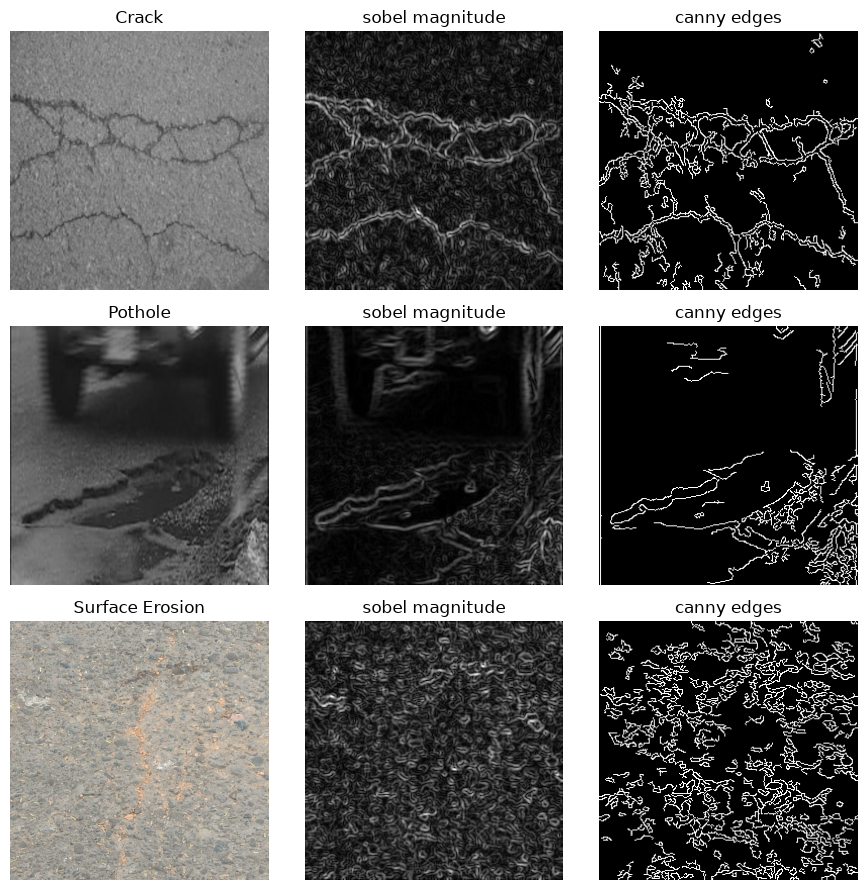

In [17]:
save_example_picture(table)

In [18]:
# every feature set with linear and rbf then one table to compare
rows = []
for set_name in FEATURE_SETS:
    x = feature_matrix(results, set_name)
    for kernel in ["linear", "rbf"]:
        print(f"running {set_name} with {kernel}")
        summary = run_svm(table, x, kernel, show_details=False)
        rows.append({"features": set_name, "numbers": x.shape[1], "svm": kernel, **summary})

comparison = pd.DataFrame(rows)
print()
print(comparison.round(3).to_string(index=False))

running strength + density with linear


running strength + density with rbf


running whole hist with linear


running whole hist with rbf


running grid hist with linear


running grid hist with rbf


... (3 outputs left out)

running grid hist + grid density with rbf


running all with linear


running all with rbf



                features  numbers    svm  numbers used  accuracy  macro f1  macro f1 std  f1 Crack  f1 Pothole  f1 Surface Erosion
      strength + density        2 linear           2.0     0.530     0.507         0.036     0.311       0.604               0.618
      strength + density        2    rbf           2.0     0.653     0.650         0.017     0.625       0.651               0.677
              whole hist        9 linear           9.0     0.481     0.470         0.028     0.573       0.448               0.388
              whole hist        9    rbf           9.0     0.506     0.501         0.035     0.586       0.484               0.436
               grid hist       36 linear          36.0     0.592     0.591         0.032     0.654       0.600               0.519
               grid hist       36    rbf          36.0     0.617     0.614         0.029     0.710       0.581               0.553
            grid density        4 linear           4.0     0.436     0.380        

In [19]:
# more detail for one set with linear
x = feature_matrix(results, "all")
print("linear svm on all features")
run_svm(table, x, "linear")

linear svm on all features


  fold 0: macro f1 0.645 C 1 gamma scale numbers 51


  fold 1: macro f1 0.653 C 1 gamma scale numbers 51


  fold 2: macro f1 0.644 C 0.01 gamma scale numbers 51


  fold 3: macro f1 0.678 C 100 gamma scale numbers 51


  fold 4: macro f1 0.650 C 10 gamma scale numbers 51
  accuracy 0.649 +- 0.012
  macro f1 0.654 +- 0.014
    f1 Crack: 0.650
    f1 Pothole: 0.702
    f1 Surface Erosion: 0.611
  confusion matrix rows are true and columns are predicted
                 Crack  Pothole  Surface Erosion
Crack              293       29              109
Pothole             45      234               64
Surface Erosion    133       61              288



{'numbers used': np.float64(51.0),
 'accuracy': np.float64(0.6488933156263832),
 'macro f1': np.float64(0.6541181073465655),
 'macro f1 std': np.float64(0.013771293523476495),
 'f1 Crack': np.float64(0.6496674057649667),
 'f1 Pothole': np.float64(0.7016491754122939),
 'f1 Surface Erosion': np.float64(0.6108165429480382)}

In [20]:
# more detail for one set with rbf
print("rbf svm on all features")
run_svm(table, x, "rbf")

rbf svm on all features


  fold 0: macro f1 0.711 C 10 gamma 0.01 numbers 51


  fold 1: macro f1 0.701 C 10 gamma 0.1 numbers 51


  fold 2: macro f1 0.665 C 10 gamma scale numbers 51


  fold 3: macro f1 0.723 C 10 gamma 0.01 numbers 51


  fold 4: macro f1 0.637 C 100 gamma 0.1 numbers 51
  accuracy 0.688 +- 0.035
  macro f1 0.687 +- 0.036
    f1 Crack: 0.747
    f1 Pothole: 0.665
    f1 Surface Erosion: 0.650
  confusion matrix rows are true and columns are predicted
                 Crack  Pothole  Surface Erosion
Crack              327       38               66
Pothole             25      232               86
Surface Erosion     92       85              305



{'numbers used': np.float64(51.0),
 'accuracy': np.float64(0.6878833870865744),
 'macro f1': np.float64(0.6871960606560857),
 'macro f1 std': np.float64(0.03555378387403292),
 'f1 Crack': np.float64(0.7474285714285714),
 'f1 Pothole': np.float64(0.664756446991404),
 'f1 Surface Erosion': np.float64(0.6496272630457934)}

In [21]:
# linear and rbf with and without pca on all the features
x = feature_matrix(results, "all")
rows = []
for kernel in ["linear", "rbf"]:
    for use_pca in [False, True]:
        print(f"running all with {kernel} pca {use_pca}")
        summary = run_svm(table, x, kernel, use_pca=use_pca, show_details=False)
        rows.append({"svm": kernel, "pca": use_pca, **summary})

print()
print(pd.DataFrame(rows).round(3).to_string(index=False))

running all with linear pca False


running all with linear pca True


running all with rbf pca False


running all with rbf pca True



   svm   pca  numbers used  accuracy  macro f1  macro f1 std  f1 Crack  f1 Pothole  f1 Surface Erosion
linear False          51.0     0.649     0.654         0.014     0.650       0.702               0.611
linear  True          17.6     0.632     0.635         0.019     0.651       0.680               0.575
   rbf False          51.0     0.688     0.687         0.036     0.747       0.665               0.650
   rbf  True          17.6     0.662     0.663         0.023     0.711       0.661               0.617


In [22]:
# try less and more bins on all the features
# features get worked out again for each bin count so this one is slow
original_bins = N_BINS
rows = []
for n_bins in [6, 9, 12, 18]:
    N_BINS = n_bins
    bin_results = compute_all(table)
    x = feature_matrix(bin_results, "all")
    for kernel in ["linear", "rbf"]:
        summary = run_svm(table, x, kernel, show_details=False)
        rows.append({"bins": n_bins, "svm": kernel, **summary})

# put bins back so the rest of the notebook uses the normal setting
N_BINS = original_bins

bin_comparison = pd.DataFrame(rows)
bin_comparison.round(3)

  done all 1256 images



  done all 1256 images



  done all 1256 images



  done all 1256 images



,bins,svm,numbers used,accuracy,macro f1,macro f1 std,f1 Crack,f1 Pothole,f1 Surface Erosion
0,6,linear,36.0,0.650,0.654,0.015,0.651,0.702,0.611
1,6,rbf,36.0,0.688,0.689,0.017,0.724,0.692,0.652
2,9,linear,51.0,0.649,0.654,0.014,0.650,0.702,0.611
3,9,rbf,51.0,0.688,0.687,0.036,0.747,0.665,0.650
4,12,linear,66.0,0.659,0.663,0.027,0.670,0.702,0.618
5,12,rbf,66.0,0.685,0.686,0.013,0.726,0.681,0.650
6,18,linear,96.0,0.650,0.655,0.015,0.651,0.698,0.615
7,18,rbf,96.0,0.669,0.672,0.033,0.691,0.691,0.633


In [23]:
# try 1 by 1 up to 4 by 4 grids on all the features
# features get worked out again for each grid so this one is slow
# seconds is how long the svm takes to pick C and gamma and test on all 5 folds
import time

original_grid = GRID
rows = []
for grid in [1, 2, 3, 4]:
    GRID = grid
    grid_results = compute_all(table)
    x = feature_matrix(grid_results, "all")
    for kernel in ["linear", "rbf"]:
        start = time.time()
        summary = run_svm(table, x, kernel, show_details=False)
        rows.append({"grid": f"{grid}x{grid}", "svm": kernel, **summary, "seconds": time.time() - start})

# put the grid back so the rest of the notebook uses the normal setting
GRID = original_grid

grid_comparison = pd.DataFrame(rows)
grid_comparison.round(3)

  done all 1256 images



  done all 1256 images



  done all 1256 images



  done all 1256 images



,grid,svm,numbers used,accuracy,macro f1,macro f1 std,f1 Crack,f1 Pothole,f1 Surface Erosion,seconds
0,1x1,linear,21.0,0.587,0.589,0.027,0.546,0.606,0.612,9.826
1,1x1,rbf,21.0,0.675,0.673,0.038,0.701,0.638,0.678,3.707
2,2x2,linear,51.0,0.649,0.654,0.014,0.650,0.702,0.611,56.982
3,2x2,rbf,51.0,0.688,0.687,0.036,0.747,0.665,0.650,3.787
4,3x3,linear,101.0,0.669,0.671,0.024,0.686,0.694,0.633,166.522
5,3x3,rbf,101.0,0.701,0.702,0.032,0.746,0.699,0.661,4.614
6,4x4,linear,171.0,0.629,0.632,0.029,0.656,0.656,0.584,267.582
7,4x4,rbf,171.0,0.686,0.688,0.026,0.726,0.706,0.633,6.621


In [24]:
# canny mask and hog compared with our grid hist
# canny mask only lets pixels canny marked as edges vote in the histogram
# hog is the standard version of our grid hist with lots of small cells

from skimage.feature import hog

# hog cell size in pixels so 256 by 256 gives 8 by 8 cells
HOG_CELL = 32


def masked_grid_hist(magnitude, angle, edges):
    # same as grid hist but only canny edge pixels vote
    hists = []
    for m, a, e in zip(split_into_grid(magnitude), split_into_grid(angle), split_into_grid(edges)):
        hists.append(orientation_histogram(m[e], a[e]))
    return np.concatenate(hists)


def extra_features(rgb):
    gray = prepare_image(rgb)
    magnitude, angle = sobel_gradients(gray)
    edges = canny_edges(gray)
    return {
        "canny mask hist": masked_grid_hist(magnitude, angle, edges),
        # hog works out its own gradients so it does not use our sobel
        "hog": hog(gray, orientations=N_BINS, pixels_per_cell=(HOG_CELL, HOG_CELL), cells_per_block=(2, 2)),
    }


extra = [extra_features(load_image(path)) for path in table["full_path"]]

rows = []
for name in ["canny mask hist", "hog"]:
    x = np.array([e[name] for e in extra])
    for kernel in ["linear", "rbf"]:
        summary = run_svm(table, x, kernel, show_details=False)
        rows.append({"features": name, "svm": kernel, **summary})

# our grid hist and all from before to compare against
for name in ["grid hist", "all"]:
    x = feature_matrix(results, name)
    for kernel in ["linear", "rbf"]:
        summary = run_svm(table, x, kernel, show_details=False)
        rows.append({"features": name, "svm": kernel, **summary})

extra_comparison = pd.DataFrame(rows)
extra_comparison.round(3)

,features,svm,numbers used,accuracy,macro f1,macro f1 std,f1 Crack,f1 Pothole,f1 Surface Erosion
0,canny mask hist,linear,36.0,0.496,0.491,0.036,0.574,0.526,0.379
1,canny mask hist,rbf,36.0,0.562,0.562,0.021,0.625,0.585,0.478
2,hog,linear,1764.0,0.619,0.620,0.029,0.663,0.634,0.564
3,hog,rbf,1764.0,0.696,0.698,0.022,0.775,0.697,0.624
4,grid hist,linear,36.0,0.592,0.591,0.032,0.654,0.600,0.519
5,grid hist,rbf,36.0,0.617,0.614,0.029,0.710,0.581,0.553
6,all,linear,51.0,0.649,0.654,0.014,0.650,0.702,0.611
7,all,rbf,51.0,0.688,0.687,0.036,0.747,0.665,0.650


In [25]:
# ablation start from all and turn one thing off at a time
# the drop shows what that feature adds that the others dont already have

ALL = ["edge_strength", "edge_density", "whole_hist", "grid_hist", "grid_density"]
SOBEL = ["edge_strength", "whole_hist", "grid_hist"]
CANNY = ["edge_density", "grid_density"]

ablation = {"all": ALL}
for name in ALL:
    ablation["without " + name] = [n for n in ALL if n != name]
ablation["without sobel"] = CANNY
ablation["without canny"] = SOBEL

# add them to the feature sets so feature matrix can find them
FEATURE_SETS.update(ablation)

rows = []
for set_name in ablation:
    x = feature_matrix(results, set_name)
    for kernel in ["linear", "rbf"]:
        summary = run_svm(table, x, kernel, show_details=False)
        rows.append({"run": set_name, "svm": kernel, **summary})

ablation_results = pd.DataFrame(rows)

# how much macro f1 drops compared to all for the same svm
base = ablation_results[ablation_results["run"] == "all"].set_index("svm")["macro f1"]
ablation_results["drop"] = ablation_results["macro f1"] - ablation_results["svm"].map(base)
ablation_results.round(3)

,run,svm,numbers used,accuracy,macro f1,macro f1 std,f1 Crack,f1 Pothole,f1 Surface Erosion,drop
0,all,linear,51.0,0.649,0.654,0.014,0.650,0.702,0.611,0.000
1,all,rbf,51.0,0.688,0.687,0.036,0.747,0.665,0.650,0.000
2,without edge_strength,linear,50.0,0.623,0.627,0.030,0.633,0.663,0.585,-0.028
3,without edge_strength,rbf,50.0,0.652,0.651,0.037,0.715,0.641,0.600,-0.036
4,without edge_density,linear,50.0,0.648,0.653,0.012,0.650,0.701,0.609,-0.001
5,without edge_density,rbf,50.0,0.675,0.674,0.037,0.743,0.647,0.633,-0.014
6,without whole_hist,linear,42.0,0.651,0.656,0.018,0.656,0.702,0.611,0.002
7,without whole_hist,rbf,42.0,0.686,0.685,0.041,0.742,0.673,0.643,-0.002
8,without grid_hist,linear,15.0,0.588,0.589,0.031,0.550,0.603,0.613,-0.065
9,without grid_hist,rbf,15.0,0.652,0.650,0.039,0.674,0.628,0.649,-0.037


In [26]:
# robustness on all the features with linear and rbf
# slow because every test image is changed 15 ways and features are worked out again

def edge_test_features(images, k):
    # edge features dont depend on the fold so k is not used
    return feature_matrix([image_features(img) for img in images], "all")


x = feature_matrix(results, "all")
robustness = run_robustness(table, x, edge_test_features)
robustness.round(3)

,svm,test images,macro f1,same as normal
0,linear,normal,0.654,1.000
1,linear,darker x0.6,0.663,0.968
2,linear,brighter x1.4,0.605,0.800
3,linear,gamma 0.6,0.659,0.916
4,linear,gamma 1.6,0.633,0.914
5,linear,noise 5,0.658,0.948
6,linear,noise 10,0.666,0.926
7,linear,noise 20,0.650,0.880
8,linear,blur 2,0.600,0.820
9,linear,blur 4,0.557,0.725


In [27]:
# rotation augmentation on all the features with rbf
# only rbf because linear takes very long with up to 6 copies of every image
# slow because every image is worked out 7 times

features = rotated_features(table)

# train with and without rotated copies then test on normal and rotated test images
augmentation = run_augmentation(table, features, kernels=("rbf",))
augmentation.round(3)

,test images,normal,rotate 10,rotate 45,rotate 90,rotate 180
trained on,svm,,,,,
no augmentation,rbf,0.687,0.651,0.523,0.430,0.450
small turns,rbf,0.700,0.694,0.539,0.450,0.456
quarter turns,rbf,0.677,0.664,0.585,0.677,0.676
quarter + small turns,rbf,0.711,0.691,0.595,0.674,0.687


In [28]:
# robustness of the final model trained with quarter and small turn copies
# reuses the features from the rotation augmentation cell so the copies arent worked out again
# only rbf because linear takes very long with 6 copies of every image

copies = [features[name] for name in TRAIN_SETS["quarter + small turns"] if name != "normal"]
robustness_aug = run_robustness(table, features["normal"], edge_test_features, kernels=("rbf",), copies=copies)

# rbf before and after augmentation next to each other
before = robustness[robustness["svm"] == "rbf"].set_index("test images")
after = robustness_aug.set_index("test images")
pd.DataFrame({
    "f1 before": before["macro f1"],
    "f1 after": after["macro f1"],
    "same before": before["same as normal"],
    "same after": after["same as normal"],
}).round(3)

,f1 before,f1 after,same before,same after
test images,,,,
normal,0.687,0.711,1.000,1.000
darker x0.6,0.685,0.718,0.974,0.968
brighter x1.4,0.654,0.690,0.817,0.793
gamma 0.6,0.686,0.708,0.920,0.910
gamma 1.6,0.671,0.690,0.928,0.928
noise 5,0.686,0.711,0.966,0.969
noise 10,0.685,0.712,0.936,0.950
noise 20,0.689,0.698,0.891,0.908
blur 2,0.637,0.649,0.853,0.803


In [29]:
# more detail for the final model rbf trained with rotated copies
# same as run svm so accuracy macro f1 f1 per class and confusion matrix

y = table["class_id"].to_numpy()
x = features["normal"]
fold_acc = []
fold_f1 = []
all_true = []
all_pred = []
for k in range(N_FOLDS):
    train, val, test = get_split(table, k)
    model = fit_best_svm(x, y, train, val, "rbf", copies)
    predicted = model.predict(x[test.index])
    fold_acc.append(accuracy_score(y[test.index], predicted))
    fold_f1.append(f1_score(y[test.index], predicted, average="macro"))
    all_true.extend(y[test.index])
    all_pred.extend(predicted)

print(f"  accuracy {np.mean(fold_acc):.3f} +- {np.std(fold_acc, ddof=1):.3f}")
print(f"  macro f1 {np.mean(fold_f1):.3f} +- {np.std(fold_f1, ddof=1):.3f}")
for name, score in zip(CLASS_NAMES, f1_score(all_true, all_pred, average=None, labels=[0, 1, 2])):
    print(f"    f1 {name}: {score:.3f}")
matrix = confusion_matrix(all_true, all_pred, labels=[0, 1, 2])
print("  confusion matrix rows are true and columns are predicted")
print(pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_string())

  accuracy 0.709 +- 0.034
  macro f1 0.711 +- 0.034
    f1 Crack: 0.742
    f1 Pothole: 0.716
    f1 Surface Erosion: 0.675
  confusion matrix rows are true and columns are predicted
                 Crack  Pothole  Surface Erosion
Crack              332       25               74
Pothole             26      233               84
Surface Erosion    106       50              326


In [30]:
# robustness without normalisation to show what it fixed
# features get worked out again with NORMALISE off then it gets turned back on

NORMALISE = False
plain = feature_matrix(compute_all(table), "all")
robustness_plain = run_robustness(table, plain, edge_test_features, kernels=("rbf",))
NORMALISE = True

# rbf macro f1 for each version of the pipeline next to each other
pd.DataFrame({
    "no normalisation": robustness_plain.set_index("test images")["macro f1"],
    "normalisation": robustness[robustness["svm"] == "rbf"].set_index("test images")["macro f1"],
    "+ rotation aug": robustness_aug.set_index("test images")["macro f1"],
}).round(3)

  done all 1256 images



,no normalisation,normalisation,+ rotation aug
test images,,,
normal,0.698,0.687,0.711
darker x0.6,0.569,0.685,0.718
brighter x1.4,0.647,0.654,0.690
gamma 0.6,0.658,0.686,0.708
gamma 1.6,0.681,0.671,0.690
noise 5,0.699,0.686,0.711
noise 10,0.694,0.685,0.712
noise 20,0.692,0.689,0.698
blur 2,0.671,0.637,0.649


In [31]:
# canny thresholds worked out per image instead of fixed 50 150
# only the lighting changes because thats what per image thresholds are meant to fix

lighting = ["darker x0.6", "brighter x1.4", "gamma 0.6", "gamma 1.6"]
all_changes = TEST_IMAGE_CHANGES
TEST_IMAGE_CHANGES = {name: all_changes[name] for name in lighting}

CANNY_AUTO = True
auto = feature_matrix(compute_all(table), "all")
robustness_auto = run_robustness(table, auto, edge_test_features, kernels=("rbf",))
CANNY_AUTO = False

# put every change back for anything run after this
TEST_IMAGE_CHANGES = all_changes

fixed = robustness[robustness["svm"] == "rbf"].set_index("test images")["macro f1"]
auto_vs_fixed = pd.DataFrame({
    "fixed 50 150": fixed[["normal"] + lighting],
    "per image": robustness_auto.set_index("test images")["macro f1"],
})
print(auto_vs_fixed.round(3).to_string())
print()
print("average under the lighting changes")
print(auto_vs_fixed.loc[lighting].mean().round(3).to_string())

  done all 1256 images



               fixed 50 150  per image
test images                           
normal                0.687      0.668
darker x0.6           0.685      0.672
brighter x1.4         0.654      0.648
gamma 0.6             0.686      0.640
gamma 1.6             0.671      0.621

average under the lighting changes
fixed 50 150    0.674
per image       0.645


In [32]:
# two label images with the normal model and the final model trained with rotated copies
# uses copies from the final robustness cell

amb = load_ambiguous()
amb_x = feature_matrix([image_features(load_image(p)) for p in amb["full_path"]], "all")

normal_model = run_ambiguous(table, feature_matrix(results, "all"), amb, amb_x)
final_model = run_ambiguous(table, features["normal"], amb, amb_x, kernels=("rbf",), copies=copies)
final_model["svm"] = "rbf + rotation aug"

pd.concat([normal_model, final_model]).round(3)

,svm,labels,images,guessed label a,guessed label b,guessed neither,right
0,linear,Crack + Surface Erosion,7,3,3,1,0.857
1,linear,Pothole + Surface Erosion,37,6,26,5,0.865
2,rbf,Crack + Surface Erosion,7,2,3,2,0.714
3,rbf,Pothole + Surface Erosion,37,6,30,1,0.973
0,rbf + rotation aug,Crack + Surface Erosion,7,3,4,0,1.000
1,rbf + rotation aug,Pothole + Surface Erosion,37,8,26,3,0.919
